In [28]:
#!/usr/bin/env python
# coding: utf-8

# In[32]:
import torch
import torch.nn as nn
import ltn
import numpy as np
import matplotlib.pyplot as plt

In [29]:
# In[33]:
# Configure o LTNtorch para usar o dispositivo apropriado.
ltn.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {ltn.device}")

Using device: cpu


In [30]:
# In[34]:
# 1. DEFINIR CONECTIVOS LÓGICOS E QUANTIFICADORES (REQUERIDOS NO LTNTORCH)
Not = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg = ltn.fuzzy_ops.SatAgg()

In [31]:
# In[35]:
# 2. CRIAR OBJETOS LTN (Constantes e Variáveis)
red_ball = ltn.Constant(torch.tensor([1.0, 0.0, 0.0]), trainable=False)
blue_cube = ltn.Constant(torch.tensor([0.0, 0.0, 1.0]), trainable=False)

balls = ltn.Variable("balls", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.5, 0.0, 0.5],
]))
cubes = ltn.Variable("cubes", torch.tensor([
    [0.0, 0.0, 1.0],
    [1.0, 1.0, 0.0],
    [0.5, 0.5, 0.5],
]))

In [32]:
# In[36]:
# 3. DEFINIR PREDICADOS (Propriedades/relações lógicas)
class ColorPredicate(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        if hasattr(x, 'value'):
            x = x.value
        return self.network(x).squeeze()

In [33]:
is_red = ltn.Predicate(ColorPredicate())
is_blue = ltn.Predicate(ColorPredicate())
is_round = ltn.Predicate(ColorPredicate())

In [34]:
# 4. DEFINIR AXIOMAS LÓGICOS (Base de conhecimento)
def axioms():
    facts = [
        is_red(red_ball),
        is_blue(blue_cube),
        is_round(red_ball),
        Not(is_round(blue_cube))
    ]
    rules = [
        Forall(balls, is_round(balls)),
        Forall(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)),
            Implies(is_red(ltn.Variable("x", torch.randn(10, 3, device=ltn.device))),
            is_round(ltn.Variable("x", torch.randn(10, 3, device=ltn.device)))))
    ]
    all_axioms = facts + rules
    return sat_agg(*all_axioms)

In [35]:
# 5. VERIFICAÇÃO DE SATISFATÓRIA (Raciocínio)
def check_satisfiability():
    sat_level = axioms()
    print(f"Knowledge base satisfaction level: {sat_level.item():.4f}")
    return sat_level

In [36]:
# 6. TREINAMENTO DOS PREDICADOS (Aprendendo com os dados)
def train_predicates(epochs=100):
    parameters = list(is_red.model.parameters()) + \
                 list(is_blue.model.parameters()) + \
                 list(is_round.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("\n=== TRAINING PREDICATES ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat_loss = 1 - axioms()
        sat_loss.backward()
        optimizer.step()
        if epoch % 20 == 0:
            print(f"Epoch {epoch}: Satisfaction = {1-sat_loss.item():.4f}")

In [37]:
# In[43]:
# 7. QUERYING THE KNOWLEDGE BASE (Inference)
def query_knowledge_base():
    print("\n=== QUERYING KNOWLEDGE BASE ===")
    # Query 1: Is the red ball red?
    query1 = is_red(red_ball)
    print(f"Q1: Is the red ball red? A: {query1.value.item():.4f}")
    
    # Query 2: Is the blue cube round?
    query2 = is_round(blue_cube)
    print(f"Q2: Is the blue cube round? A: {query2.value.item():.4f}")
    
    # Query 3: Are all balls round? (Universal quantification)
    all_balls_round = Forall(balls, is_round(balls))
    print(f"Q3: Are all balls round? A: {all_balls_round.value.item():.4f}")

In [38]:
# 8. EXECUTE O EXEMPLO COMPLETO
print("=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===")
initial_sat = check_satisfiability()
train_predicates(epochs=100)
final_sat = check_satisfiability()
query_knowledge_base()
print("\n=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===")
print("1. LTNObjects encapsulam tensores com significado lógico.")
print("2. Constantes representam entidades específicas")
print("3. As variáveis representam conjuntos quantificáveis")
print("4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]")
print("5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.")
print("6. Os quantificadores (Forall, Exists) agregam sobre a variávels")
print("7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.")
print("8. A função SatAgg combina múltiplos axiomas em uma única pontuação de satisfação.")


=== EXEMPLO DE RACIOCÍNIO LÓGICO LTN ===
Knowledge base satisfaction level: 0.5207

=== TRAINING PREDICATES ===
Epoch 0: Satisfaction = 0.5212
Epoch 20: Satisfaction = 0.6655
Epoch 40: Satisfaction = 0.7772
Epoch 60: Satisfaction = 0.8472
Epoch 80: Satisfaction = 0.9045
Knowledge base satisfaction level: 0.9488

=== QUERYING KNOWLEDGE BASE ===
Q1: Is the red ball red? A: 0.9651
Q2: Is the blue cube round? A: 0.0903
Q3: Are all balls round? A: 0.9444

=== PRINCIPAIS INFORMAÇÕES SOBRE O LTNObjects ===
1. LTNObjects encapsulam tensores com significado lógico.
2. Constantes representam entidades específicas
3. As variáveis representam conjuntos quantificáveis
4. Os predicados mapeiam LTNObjects para valores de verdade [0,1]
5. Os conectivos lógicos (E, Ou, Não, Implica) operam sobre valores de verdade.
6. Os quantificadores (Forall, Exists) agregam sobre a variávels
7. No LTNTorch, você deve definir explicitamente todos os conectivos lógicos.
8. A função SatAgg combina múltiplos axiomas em

In [39]:
# ==============================================================================
# EXTENSÃO: DIFERENTES FORMAS DE IGUALDADE EM LTN (Extensão Original)
# ==============================================================================
# In[45]:
print("\n" + "="*50)
print("EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN")
print("="*50)


EXTENSION: DIFFERENT FORMS OF EQUALITY IN LTN


In [40]:
Not_eq = ltn.Connective(ltn.fuzzy_ops.NotStandard())
And_eq = ltn.Connective(ltn.fuzzy_ops.AndProd())
Or_eq = ltn.Connective(ltn.fuzzy_ops.OrProbSum())
Implies_eq = ltn.Connective(ltn.fuzzy_ops.ImpliesReichenbach())
Forall_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMeanError(p=2), quantifier="f")
Exists_eq = ltn.Quantifier(ltn.fuzzy_ops.AggregPMean(p=2), quantifier="e")
sat_agg_eq = ltn.fuzzy_ops.SatAgg()

In [41]:
red_object1 = ltn.Constant(torch.tensor([1.0, 0.0, 0.0], device=ltn.device), trainable=True)
red_object2 = ltn.Constant(torch.tensor([0.95, 0.05, 0.0], device=ltn.device), trainable=True)
blue_object = ltn.Constant(torch.tensor([0.0, 0.0, 1.0], device=ltn.device), trainable=True)

objects = ltn.Variable("objetos", torch.tensor([
    [1.0, 0.0, 0.0],
    [0.95, 0.05, 0.0],
    [0.0, 0.0, 1.0],
    [0.0, 1.0, 0.0],
], device=ltn.device))
print("Experimento sobre igualdade: configuração concluída!")

# In[46]: 1. Igualdade diagonal LTN
print("\n" + "-"*30)
print("1. IGUALDADE DIAGONAL LTN")
print("-"*30)

Experimento sobre igualdade: configuração concluída!

------------------------------
1. IGUALDADE DIAGONAL LTN
------------------------------


In [42]:
class DiagonalEquality(nn.Module):
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return 0.5 * (cos_sim + 1.0)

In [43]:
# Teste da Igualdade diagonal euclidiana
Equal_Diag = ltn.Predicate(DiagonalEquality().to(ltn.device))

In [44]:
def axioms_withEquality_Diag():
    axioms = [
        Forall_eq(objects, Equal_Diag(objects, objects)),
        Equal_Diag(red_object1, red_object2),
        Equal_Diag(red_object2, red_object1),
        Implies_eq(And_eq(Equal_Diag(red_object1, red_object2), Equal_Diag(red_object2, red_object1)), Equal_Diag(red_object1, red_object1)),
        Not_eq(Equal_Diag(red_object1, blue_object))
    ]
    return sat_agg_eq(*axioms)

In [45]:
print("Testando a igualdade diagonal...")
sat_diag = axioms_withEquality_Diag()
print(f"Satisfação KB de igualdade diagonal: {sat_diag.item():.4f}")
print(f"P: Os dois objetos vermelhos são iguais? R: {Equal_Diag(red_object1, red_object2).value.item():.4f}")
print(f"P: Um objeto vermelho é igual a um objeto azul? R: {Equal_Diag(red_object1, blue_object).value.item():.4f}")

# In[50]: 2. Igualdade de cosseno
print("\n" + "-"*30)
print("2. IGUALDADE DE COSSENO.")
print("-"*30)

Testando a igualdade diagonal...
Satisfação KB de igualdade diagonal: 0.7764
P: Os dois objetos vermelhos são iguais? R: 0.9993
P: Um objeto vermelho é igual a um objeto azul? R: 0.5000

------------------------------
2. IGUALDADE DE COSSENO.
------------------------------


In [46]:
class CosineEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.tensor(1.0, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        cos_sim = torch.nn.functional.cosine_similarity(x_val, y_val, dim=-1)
        return torch.sigmoid(self.temperature * (cos_sim + 1.0) / 2.0)
        
Equal_Cos = ltn.Predicate(CosineEquality().to(ltn.device))

In [47]:
def axioms_withEquality_Cos():
    parameters = list(Equal_Cos.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento da Igualdade do Cosseno...")
    for epoch in range(200):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Equal_Cos(red_object2, red_object1), Not_eq(Equal_Cos(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Época {epoch}: Satisfatibilidade da igualdade do cosseno = {sat.item():.4f}, Temp = {Equal_Cos.model.temperature.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Cos(objects, objects)), Equal_Cos(red_object1, red_object2), Not_eq(Equal_Cos(red_object1, blue_object)))

sat_cos = axioms_withEquality_Cos()
print(f"Satisfatibilidade KB da Igualdade do Cosseno Final: {sat_cos.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (cosseno)? A: {Equal_Cos(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: {Equal_Cos(red_object1, blue_object).value.item():.4f}")


Treinamento da Igualdade do Cosseno...
Época 0: Satisfatibilidade da igualdade do cosseno = 0.6112, Temp = 1.1000
Época 50: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5738
Época 100: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5680
Época 150: Satisfatibilidade da igualdade do cosseno = 0.6255, Temp = 1.5687
Satisfatibilidade KB da Igualdade do Cosseno Final: 0.5793
Q: Os dois objetos vermelhos são iguais (cosseno)? A: 0.8275
Q: O objeto vermelho é igual ao objeto azul (cosseno)? A: 0.6866


In [48]:
# In[51]: 3. Igualdade Euclidiana
print("\n" + "-"*30)
print("3. IGUALDADE EUCLIDIANA")
print("-"*30)


------------------------------
3. IGUALDADE EUCLIDIANA
------------------------------


In [49]:
class EuclideanEquality(nn.Module):
    def __init__(self):
        super().__init__()
        self.gamma = nn.Parameter(torch.tensor(0.5, device=ltn.device))
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'value') else x
        y_val = y.value if hasattr(y, 'value') else y
        distance = torch.sum(torch.square(x_val - y_val), dim=-1)
        return torch.exp(-self.gamma * distance)

Equal_Eucl = ltn.Predicate(EuclideanEquality().to(ltn.device))


In [50]:
def axioms_withEquality_Eucl():
    parameters = list(Equal_Eucl.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.1)
    print("Treinamento em Igualdade Euclidiana...")
    for epoch in range(150):
        optimizer.zero_grad()
        axioms = [Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Equal_Eucl(red_object2, red_object1), Not_eq(Equal_Eucl(red_object1, blue_object))]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 30 == 0:
            print(f"Época {epoch}: Satisfatibilidade da Igualdade Euclidiana = {sat.item():.4f}, Gamma = {Equal_Eucl.model.gamma.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Eucl(objects, objects)), Equal_Eucl(red_object1, red_object2), Not_eq(Equal_Eucl(red_object1, blue_object)))

sat_eucl = axioms_withEquality_Eucl()
print(f"Satisfatibilidade final da igualdade euclidiana KB: {sat_eucl.item():.4f}")
print(f"Q: Os dois objetos vermelhos são iguais (euclidianos)? A: {Equal_Eucl(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: {Equal_Eucl(red_object1, blue_object).value.item():.4f}")


Treinamento em Igualdade Euclidiana...
Época 0: Satisfatibilidade da Igualdade Euclidiana = 0.8160, Gamma = 0.6000
Época 30: Satisfatibilidade da Igualdade Euclidiana = 0.9903, Gamma = 2.2782
Época 60: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4738
Época 90: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4658
Época 120: Satisfatibilidade da Igualdade Euclidiana = 0.9905, Gamma = 2.4479
Satisfatibilidade final da igualdade euclidiana KB: 0.9917
Q: Os dois objetos vermelhos são iguais (euclidianos)? A: 0.9879
Q: O objeto vermelho é igual ao objeto azul (euclidiano)? A: 0.0076


In [51]:
# In[52]: 4. Igualdade de Variedades Aprendíveis
print("\n" + "-"*30)
print("4. IGUALDADE DE VARIEDADES APRENDÍVEIS")
print("-"*30)

class LearnableEquality(nn.Module):
    def __init__(self, input_dim=3):
        super(LearnableEquality, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim * 2, 64), nn.ELU(),
            nn.Linear(64, 32), nn.ELU(),
            nn.Linear(32, 1), nn.Sigmoid()
        )
    def forward(self, x, y):
        x_val = x.value if hasattr(x, 'valor') else x
        y_val = y.value if hasattr(y, 'valor') else y
        cat_inputs = torch.cat([x_val, y_val], dim=-1)
        return self.net(cat_inputs).squeeze()

Equal_Learned = ltn.Predicate(LearnableEquality(input_dim=3).to(ltn.device))



------------------------------
4. IGUALDADE DE VARIEDADES APRENDÍVEIS
------------------------------


In [52]:
def axioms_withEquality_Learned():
    parameters = list(Equal_Learned.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    print("Treinaento da Rede de Igualdade aprodível...")
    for epoch in range(300):
        optimizer.zero_grad()
        axioms = [
            Forall_eq(objects, Equal_Learned(objects, objects)),
            Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1),
            Not_eq(Equal_Learned(red_object1, blue_object)), Not_eq(Equal_Learned(blue_object, red_object1)),
            Implies_eq(And_eq(Equal_Learned(red_object1, red_object2), Equal_Learned(red_object2, red_object1)), Equal_Learned(red_object1, red_object1))
        ]
        sat = sat_agg_eq(*axioms)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: Satisfatibilidade com a igualdade aprendível= {sat.item():.4f}")
    return sat_agg_eq(Forall_eq(objects, Equal_Learned(objects, objects)), Equal_Learned(red_object1, red_object2), Not_eq(Equal_Learned(red_object1, blue_object)))

sat_learned = axioms_withEquality_Learned()
print(f"Satisfação final com a base de conhecimento sobre igualdade aprendível: {sat_learned.item():.4f}")
print(f"Q:Os dois objetos vermelhos são iguais (Aprendido)? A: {Equal_Learned(red_object1, red_object2).value.item():.4f}")
print(f"Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: {Equal_Learned(red_object1, blue_object).value.item():.4f}")
print(f"Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: {Equal_Learned(red_object1, red_object1).value.item():.4f}")


Treinaento da Rede de Igualdade aprodível...
Epoch 0: Satisfatibilidade com a igualdade aprendível= 0.5376
Epoch 50: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 100: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 150: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 200: Satisfatibilidade com a igualdade aprendível= 0.7959
Epoch 250: Satisfatibilidade com a igualdade aprendível= 0.7959
Satisfação final com a base de conhecimento sobre igualdade aprendível: 0.7113
Q:Os dois objetos vermelhos são iguais (Aprendido)? A: 1.0000
Q: O objeto vermelho é igual ao objeto azul (aprendido)? A: 0.0001
Q: O objeto vermelho é igual a si mesmo (Aprendido)? A: 1.0000


In [53]:
# ==============================================================================
# NOVA EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D (Para os Alunos)
# ==============================================================================
# In[53]:
print("\n" + "="*60)
print("EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D")
print("="*60)

# ==============================================================================
# DESAFIO PARA OS ALUNOS:
# Nesta extensão, você é convidado a formalizar relações geométricas 
# usando Lógica de Primeira Ordem (FOL) e implementá-las no LTN.
#
# Definimos cinco classes de figuras geométricas 2D baseadas no centro (x,y):
# - Circle(x): A figura x é um círculo
# - Square(x): A figura x é um quadrado
# - Triangle(x): A figura x é um triângulo
# - Pentagon(x): A figura x é um pentágono
# - Hexagon(x): A figura x é um hexágono
#
# E relações espaciais entre pares de figuras:
# - LeftOf(x,y): A figura x está à esquerda da figura y
# - Above(x,y): A figura x está acima da figura y
# - Overlaps(x,y): A figura x se sobrepõe à figura y
#
# AXIOMAS EM LÓGICA DE PRIMEIRA ORDEM (Base de Conhecimento):
# 0. Pertinência: cada figura pertence à sua classe e a nenhuma outra:
#    ∀x Circle(x), ∀x ¬Square(x), ... (para cada forma)
#
# 1. Todos os círculos estão à esquerda de todos os quadrados:
#    ∀x ∀y (Circle(x) ∧ Square(y) → LeftOf(x,y))
#
# 2. Todos os triângulos estão acima de todos os círculos:
#    ∀x ∀y (Triangle(x) ∧ Circle(y) → Above(x,y))
#
# 3. A sobreposição é simétrica:
#    ∀x ∀y (Overlaps(x,y) → Overlaps(y,x))
#
# 4. Nenhum objeto se sobrepõe a si mesmo:
#    ∀x ¬Overlaps(x,x)
#
# 5. Todos os quadrados estão à esquerda de todos os pentágonos:
#    ∀x ∀y (Square(x) ∧ Pentagon(y) → LeftOf(x,y))
#
# 6. Todos os círculos estão acima de todos os hexágonos:
#    ∀x ∀y (Circle(x) ∧ Hexagon(y) → Above(x,y))
#
# 7. Pentágonos e hexágonos não se sobrepõem:
#    ∀x ∀y (Pentagon(x) ∧ Hexagon(y) → ¬Overlaps(x,y))
#
# 8. Todo círculo tem algum pentágono à sua direita:
#    ∀x (Circle(x) → ∃y (Pentagon(y) ∧ LeftOf(x,y)))
# ==============================================================================

# 1. GERAÇÃO DE DADOS — cada forma em uma região do plano: (escala, deslocamento)
SHAPE_REGIONS = {
    "circle":   ([4.0, 10.0], [0.0, 0.0]),    # faixa esquerda
    "square":   ([4.0, 10.0], [6.0, 0.0]),    # faixa central-direita
    "triangle": ([10.0, 4.0], [0.0, 6.0]),    # faixa superior
    "pentagon": ([3.0, 10.0], [11.0, 0.0]),   # à direita dos quadrados
    "hexagon":  ([10.0, 3.0], [0.0, -4.0]),   # abaixo de tudo
}

def generate_random_shapes(num_per_shape=10):
    return {
        name: torch.rand(num_per_shape, 2, device=ltn.device) * torch.tensor(scale, device=ltn.device)
              + torch.tensor(offset, device=ltn.device)
        for name, (scale, offset) in SHAPE_REGIONS.items()
    }

# 2. PREDICADOS NEURAIS
class ShapeClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16), nn.ReLU(),
            nn.Linear(16, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

class LearnableSpatialRelation(nn.Module):
    def __init__(self, feature_extractor):
        super().__init__()
        self.feature_extractor = feature_extractor
        self.net = nn.Sequential(
            nn.Linear(1, 16), nn.ReLU(),
            nn.Linear(16, 1), nn.Sigmoid()
        )
    def forward(self, x, y):
        # o LTN já faz o broadcasting dos pares (x, y): sem unsqueeze aqui
        return self.net(self.feature_extractor(x, y)).squeeze(-1)

def left_of_features(x, y):
    return (y[..., 0] - x[..., 0]).unsqueeze(-1)

def above_features(x, y):
    return (x[..., 1] - y[..., 1]).unsqueeze(-1)

def distance_features(x, y):
    return torch.norm(x - y, dim=-1, keepdim=True)

is_circle = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_square = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_triangle = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_pentagon = ltn.Predicate(ShapeClassifier().to(ltn.device))
is_hexagon = ltn.Predicate(ShapeClassifier().to(ltn.device))
left_of = ltn.Predicate(LearnableSpatialRelation(left_of_features).to(ltn.device))
above = ltn.Predicate(LearnableSpatialRelation(above_features).to(ltn.device))
overlaps = ltn.Predicate(LearnableSpatialRelation(distance_features).to(ltn.device))

shape_preds = {
    "circle": is_circle, "square": is_square, "triangle": is_triangle,
    "pentagon": is_pentagon, "hexagon": is_hexagon,
}

# 3. AXIOMAS LÓGICOS
def define_geo_axioms(data):
    c = ltn.Variable("c", data["circle"])
    s = ltn.Variable("s", data["square"])
    t = ltn.Variable("t", data["triangle"])
    p = ltn.Variable("p", data["pentagon"])
    h = ltn.Variable("h", data["hexagon"])
    vars_by_shape = {"circle": c, "square": s, "triangle": t, "pentagon": p, "hexagon": h}

    # Pertinência: ∀x Forma(x) e ∀x ¬OutraForma(x)
    axioms = []
    for name, var in vars_by_shape.items():
        axioms.append(Forall(var, shape_preds[name](var)))
        for other, pred in shape_preds.items():
            if other != name:
                axioms.append(Forall(var, Not(pred(var))))

    axioms += [
        Forall([c, s], Implies(And(is_circle(c), is_square(s)), left_of(c, s))),
        Forall([t, c], Implies(And(is_triangle(t), is_circle(c)), above(t, c))),
        Forall([c, s], Implies(overlaps(c, s), overlaps(s, c))),
        Forall(c, Not(overlaps(c, c))),
        Forall(s, Not(overlaps(s, s))),
        Forall(t, Not(overlaps(t, t))),
        Forall(p, Not(overlaps(p, p))),
        Forall(h, Not(overlaps(h, h))),
        Forall([s, p], Implies(And(is_square(s), is_pentagon(p)), left_of(s, p))),
        Forall([c, h], Implies(And(is_circle(c), is_hexagon(h)), above(c, h))),
        Forall([p, h], Implies(And(is_pentagon(p), is_hexagon(h)), Not(overlaps(p, h)))),
        Forall(c, Exists(p, And(is_pentagon(p), left_of(c, p)))),
    ]
    return sat_agg(*axioms)

# 4. TREINAMENTO
def train_geometrical_model(epochs=300):
    parameters = []
    for pred in [*shape_preds.values(), left_of, above, overlaps]:
        parameters += list(pred.model.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)
    data = generate_random_shapes(num_per_shape=10)
    print("\n=== TREINANDO AXIOMAS GEOMÉTRICOS ===")
    for epoch in range(epochs):
        optimizer.zero_grad()
        sat = define_geo_axioms(data)
        loss = 1 - sat
        loss.backward()
        optimizer.step()
        if epoch % 60 == 0:
            print(f"Epoch {epoch}: Satisfação = {sat.item():.4f}")
    print(f"Satisfação final = {define_geo_axioms(data).item():.4f}")
    return data

# 5. TESTE EM NOVOS DADOS ALEATÓRIOS
def test_geometrical_model():
    print("\n=== TESTANDO EM NOVOS DADOS ALEATÓRIOS ===")
    test = generate_random_shapes(num_per_shape=3)
    c_test = ltn.Variable("c_test", test["circle"])
    s_test = ltn.Variable("s_test", test["square"])
    q1 = Forall([c_test, s_test], Implies(And(is_circle(c_test), is_square(s_test)), left_of(c_test, s_test)))
    print(f"Q1: Círculos à esquerda dos quadrados? Satisfação: {q1.value.item():.4f}")
    c1 = ltn.Constant(test["circle"][0])
    s1 = ltn.Constant(test["square"][0])
    p1 = ltn.Constant(test["pentagon"][0])
    h1 = ltn.Constant(test["hexagon"][0])
    print(f"Q2: Sobreposição 1º círculo/quadrado? Valor: {overlaps(c1, s1).value.item():.4f}")
    print(f"Q3: 1º círculo é círculo? Valor: {is_circle(c1).value.item():.4f}")
    print(f"Q4: 1º pentágono é pentágono? Valor: {is_pentagon(p1).value.item():.4f}")
    print(f"Q5: 1º pentágono é hexágono? Valor: {is_hexagon(p1).value.item():.4f}")
    print(f"Q6: 1º hexágono é hexágono? Valor: {is_hexagon(h1).value.item():.4f}")
    print(f"Q7: Quadrado à esquerda do pentágono? Valor: {left_of(s1, p1).value.item():.4f}")
    print(f"Q8: Círculo acima do hexágono? Valor: {above(c1, h1).value.item():.4f}")

geo_data = train_geometrical_model(epochs=300)
test_geometrical_model()


EXTENSÃO: RELAÇÕES GEOMÉTRICAS EM UM PLANO 2D

=== TREINANDO AXIOMAS GEOMÉTRICOS ===
Epoch 0: Satisfação = 0.5025
Epoch 60: Satisfação = 0.7805
Epoch 120: Satisfação = 0.8117
Epoch 180: Satisfação = 0.8231
Epoch 240: Satisfação = 0.8337
Satisfação final = 0.8413

=== TESTANDO EM NOVOS DADOS ALEATÓRIOS ===
Q1: Círculos à esquerda dos quadrados? Satisfação: 0.9998
Q2: Sobreposição 1º círculo/quadrado? Valor: 0.0000
Q3: 1º círculo é círculo? Valor: 0.9194
Q4: 1º pentágono é pentágono? Valor: 0.9040
Q5: 1º pentágono é hexágono? Valor: 0.0000
Q6: 1º hexágono é hexágono? Valor: 0.9988
Q7: Quadrado à esquerda do pentágono? Valor: 1.0000
Q8: Círculo acima do hexágono? Valor: 1.0000


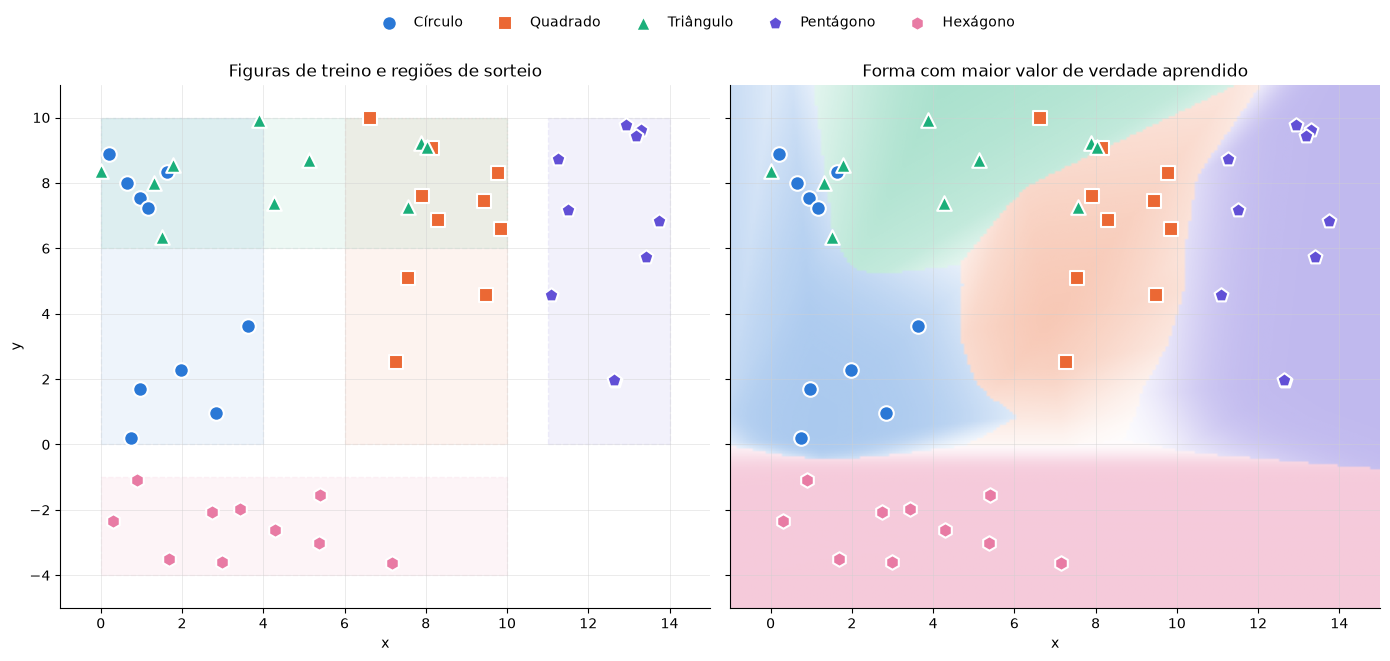

In [54]:
# ==============================================================================
# VISUALIZAÇÃO DAS FORMAS GEOMÉTRICAS
# ==============================================================================
# Esquerda: as figuras de treino no plano 2D, cada uma com o próprio formato,
#           e a região de onde cada forma é sorteada (SHAPE_REGIONS).
# Direita: o que os predicados aprenderam. Cada ponto do plano recebe a cor da
#          forma com maior valor de verdade; quanto mais forte a cor, maior o valor.
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle

SHAPE_STYLE = {
    # nome: (rótulo, marcador, cor)
    "circle":   ("Círculo",   "o", "#2a78d6"),
    "square":   ("Quadrado",  "s", "#eb6834"),
    "triangle": ("Triângulo", "^", "#1baf7a"),
    "pentagon": ("Pentágono", "p", "#6250d6"),
    "hexagon":  ("Hexágono",  "h", "#e87ba4"),
}

x_min, x_max, y_min, y_max = -1.0, 15.0, -5.0, 11.0
gx, gy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = torch.tensor(np.stack([gx.ravel(), gy.ravel()], axis=1), dtype=torch.float32, device=ltn.device)

with torch.no_grad():
    grid_var = ltn.Variable("grid", grid)
    truth = torch.stack([shape_preds[name](grid_var).value for name in SHAPE_STYLE], dim=-1).cpu().numpy()

winner = truth.argmax(axis=-1).reshape(gx.shape)
confidence = truth.max(axis=-1).reshape(gx.shape)
colors = np.array([to_rgb(color) for _, _, color in SHAPE_STYLE.values()])
learned_map = np.concatenate([colors[winner], (0.4 * confidence)[..., None]], axis=-1)

fig, (ax_data, ax_learned) = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)

for name, (label, marker, color) in SHAPE_STYLE.items():
    (sx, sy), (ox, oy) = SHAPE_REGIONS[name]
    ax_data.add_patch(Rectangle((ox, oy), sx, sy, facecolor=color, alpha=0.08,
                                edgecolor=color, linestyle="--", linewidth=1))

ax_learned.imshow(learned_map, origin="lower", extent=(x_min, x_max, y_min, y_max), aspect="auto", zorder=0)

for ax in (ax_data, ax_learned):
    for name, (label, marker, color) in SHAPE_STYLE.items():
        pts = geo_data[name].cpu().numpy()
        ax.scatter(pts[:, 0], pts[:, 1], marker=marker, s=110, c=color,
                   edgecolors="white", linewidths=1.5, label=label, zorder=3)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("x")
    ax.grid(color="#d0d0d0", linewidth=0.5, alpha=0.6, zorder=1)
    ax.spines[["top", "right"]].set_visible(False)

ax_data.set_ylabel("y")
ax_data.set_title("Figuras de treino e regiões de sorteio")
ax_learned.set_title("Forma com maior valor de verdade aprendido")
handles, labels = ax_data.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(SHAPE_STYLE), frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()